# Balmer continuum fit of an SDSS spectrum

Spectral decomposition of SDSS J092423.42+064250.6 (DR7 spectrum `spSpec-52724-1195-098.fit`). The BC is estimated following Kovačević, J., Popović, L. Č., & Kollatschny, W. 2014, AdSpR, 54, 1347 (KPK14), http://dx.doi.org/10.1016/j.asr.2013.11.035

Steps:

1. read the spectrum, correct for Galactic extinction and shift to the rest frame
2. clean the broad Balmer profiles: fit and remove Fe II, narrow lines, He II
3. fit a power law plus the KPK14 Balmer pseudo-continuum


Run it from the `examples` folder. Figures and arrays go to `results/`.

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

from agnspec import io, preprocessing as prep
from agnspec.plotting import plot_spectrum, flux_unit_from_header, plot_continuum_windows, plot_continuum_fit, plot_balmer_fit
from agnspec.utils import C_KMS, LINE_WAVELENGTHS, get_ebv
from agnspec.continuum import PowerLaw, get_continuum_mask, FeII, ContinuumModel
from agnspec.emission_lines import OIIIComplex
from agnspec.fitting import LeastSquares
from agnspec.models import AGNModel
from agnspec.balmer import BalmerPseudoContinuum, EDGE_VAC
from agnspec.optical_region import OpticalRegionModel, load_park2022_feii

In [2]:
# Configuration (all rest-frame, vacuum Angstrom)
# Fitting windows of KPK14 Sect. 2: 2650-2670, 3020-3040, the Balmer edge
# at 3646 and everything redward of 4000 A that has been cleaned.
# The width of the edge window is not given in the paper, so it is my choice.
UV_WINDOWS = [(2650.0, 2670.0), (3020.0, 3040.0)]
EDGE_WINDOW = (3640.0, 3650.0)
RED_WINDOW = (4000.0, 5500.0)      # upper limit is my choice (the data end at ~5790)
STAGE1_RANGE = (4000.0, 5500.0)    # paper: 4000-5500 A
PL_PIVOT = 5100.0                  # the paper uses F_5600 (l/5600)^alpha

## 1) Load spectrum and do preliminary cleaning.

In [3]:
input_spec = 'spSpec-52724-1195-098.fit'
outdir = 'results'
os.makedirs(outdir, exist_ok=True)

wave_obs, flux_obs, err_obs, hdr = io.read_spectrum(input_spec)
FLUX_UNIT = flux_unit_from_header(hdr)
z = float(hdr["Z"])
src_ra, src_dec = hdr['RA'], hdr['DEC']

# Galactic E(B-V) from the IRSA dust service (needs an internet connection)
ebv = get_ebv(src_ra, src_dec)
if np.isnan(ebv):
    ebv = 0.0406    # the value used for the reference run of this notebook

spSpec-52724-1195-098.fit: z = 0.588403, E(B-V) = 0.0406, 3858 pixels, 3794-9221 A (obs)
rest-frame range: 2389-5789 A


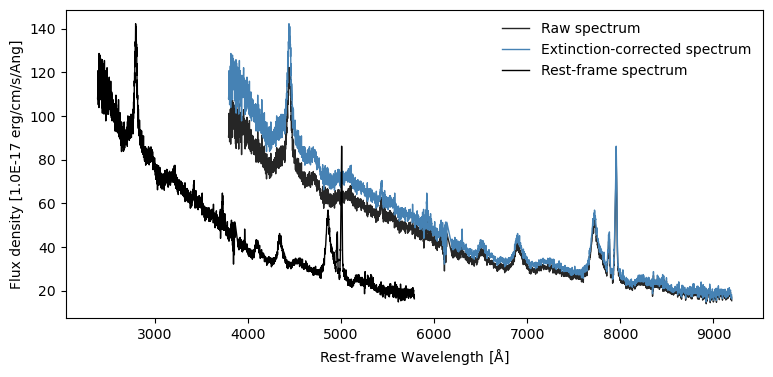

In [4]:
print(f"{os.path.basename(input_spec)}: z = {z:.6f}, E(B-V) = {ebv:.4f}, "
  f"{len(wave_obs)} pixels, {wave_obs[0]:.0f}-{wave_obs[-1]:.0f} A (obs)")

# Bad pixels: spSpec marks them with error <= 0
good = prep.mask_bad_pixels(wave_obs, flux_obs, err_obs)
wave_obs, flux_obs, err_obs = wave_obs[good], flux_obs[good], err_obs[good]

# CCM89, R_V = 3.1, applied at OBSERVED wavelengths, flux AND error
flux_dr, err_dr = prep.deredden_spectrum(wave_obs, flux_obs, error=err_obs,
                                         ebv=ebv, rv=3.1, law="ccm89")
# Rest frame: wavelength only. Flux density and error are NOT touched.
wave = prep.to_rest_frame(wave_obs, z)
flux, err = flux_dr, err_dr
print(f"rest-frame range: {wave[0]:.0f}-{wave[-1]:.0f} A")

fig, ax = plt.subplots(figsize=(9, 4))
plot_spectrum(wave_obs, flux_obs, ax=ax, stage="raw", flux_unit=FLUX_UNIT)
plot_spectrum(wave_obs, flux_dr, ax=ax, stage="dered", flux_unit=FLUX_UNIT)
plot_spectrum(wave, flux, ax=ax, stage="rest", flux_unit=FLUX_UNIT)

fig.savefig(os.path.join(outdir, "00_preprocessing.png"), dpi=130, bbox_inches="tight")

<Axes: xlabel='Rest-frame Wavelength [$\\mathrm{\\AA}$]', ylabel='Flux density [1.0E-17 erg/cm/s/Ang]'>

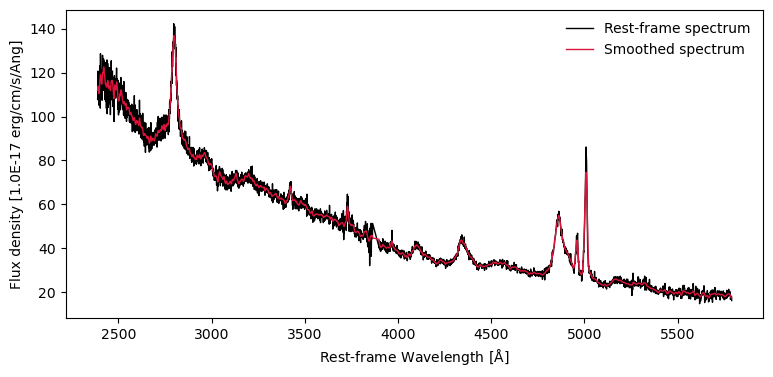

In [5]:
# Plot smoothed spectrum (for visual inspection only, not used in fitting)
fig, ax = plt.subplots(figsize=(9, 4))
plot_spectrum(wave, flux, ax=ax, stage="rest", flux_unit=FLUX_UNIT)
flux_smooth = prep.smooth_spectrum(flux,sigma=3)
plot_spectrum(wave, flux_smooth, ax=ax, stage="smooth", flux_unit=FLUX_UNIT)


## Stage 2: clean the broad Balmer profiles
### 2a) Fit a power law and Fe II continuum, then subtract both to get the emission-line flux

<Axes: xlabel='Rest-frame Wavelength [$\\mathrm{\\AA}$]', ylabel='Flux density [1.0E-17 erg/cm/s/Ang]'>

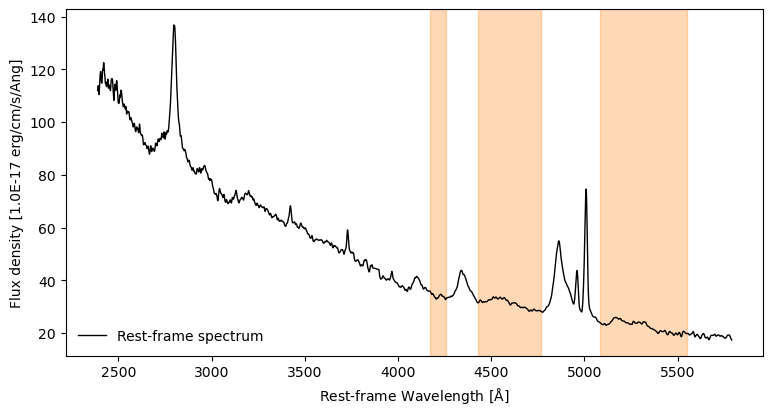

In [6]:
# Define continuum windows for fitting the continuum. 
# These are wavelength ranges that are relatively free of emission lines and 
# can be used to estimate the underlying continuum level.
# From Greene & Ho (2005, ApJ, 630, 122); The first window is to include Ca II K&H.
continuum_windows = [ [4170, 4260], [4430, 4770], [5080, 5550], [6050, 6200], [6890, 7010]]  
continuum_mask = get_continuum_mask(wave, continuum_windows)
plot_continuum_windows(wave, flux_smooth, continuum_mask, flux_unit=FLUX_UNIT)

Fe II template covers 4000-5600 A
continuum fit: chi2/dof = 1.13
   powerlaw_amplitude                23.09 +/- 0.073
   powerlaw_alpha                   -1.916 +/- 0.017
   feii_amplitude                    8.206 +/- 0.28
   feii_broadening                     911 +/- 81
   feii_velocity_shift               93.49 +/- 84


<Axes: xlabel='Rest-frame Wavelength [$\\mathrm{\\AA}$]', ylabel='Flux density [1.0E-17 erg/cm/s/Ang]'>

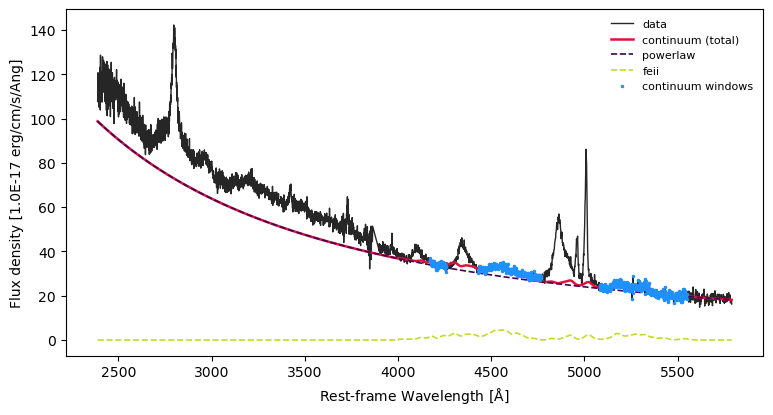

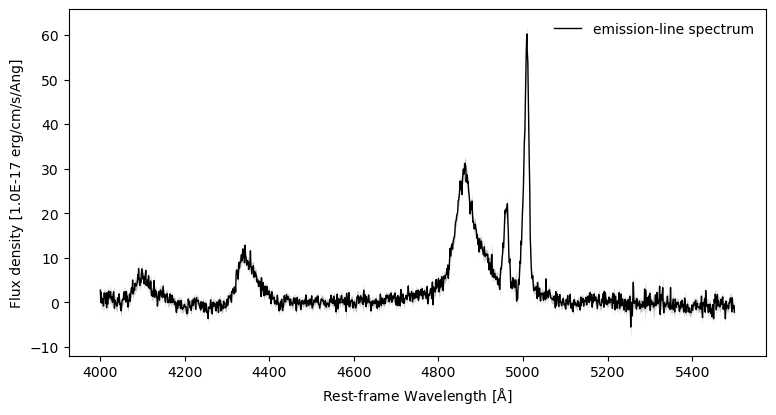

In [7]:
# Fit a power-law + Fe II continuum to the spectrum using the defined continuum windows.
ls = LeastSquares(maxfev=20000)
fe_w, fe_f = load_park2022_feii()
print(f"Fe II template covers {fe_w.min():.0f}-{fe_w.max():.0f} A")   # must span your windows

cont = ContinuumModel([PowerLaw(wave0=5100.0), FeII(fe_w, fe_f)])
res_c = ls.fit(wave[continuum_mask], flux[continuum_mask], err[continuum_mask], cont)

print(f"continuum fit: chi2/dof = {res_c.chi2/res_c.dof:.2f}")
for k, v, e in zip(res_c.param_names, res_c.params, res_c.param_errors):
    print(f"   {k:26s} {v:12.4g} +/- {e:.2g}")

# evaluate over the whole spectrum, then subtract
cont_flux = cont.model(wave, *res_c.params)
comps = cont.component_models(wave, res_c.params)    # {"powerlaw": ..., "feii": ...}

region = (wave >= 4000) & (wave <= 5500)
wave_l = wave[region]
line_flux = flux[region] - cont_flux[region]         # emission-line spectrum
err_l = err[region]

# diagnostics
plot_continuum_fit(wave, flux, cont_flux, components=comps, mask=continuum_mask, flux_unit=FLUX_UNIT)
plot_spectrum(wave_l, line_flux, error=err_l, stage="rest",
              label="emission-line spectrum", flux_unit=FLUX_UNIT)

### 2b) Fit [OIII] to get the narrow-line kinematics

In [8]:
sel = (wave_l > 4940) & (wave_l < 5060)
oiii = OIIIComplex(include_wing=False)
res_o = ls.fit(wave_l[sel], line_flux[sel], err_l[sel], oiii)
pars = oiii.component_fluxes(res_o.params)
amp, cen, sig = pars["oiii_5007"]
narrow_sigma_v = C_KMS * sig / cen
narrow_dv = C_KMS * (cen - LINE_WAVELENGTHS["OIII_5007"]) / LINE_WAVELENGTHS["OIII_5007"]
print(f"[OIII]5007 core: sigma = {narrow_sigma_v:.0f} km/s (FWHM {2.355*narrow_sigma_v:.0f}), "
  f"dv = {narrow_dv:+.0f} km/s")
if not (40 < narrow_sigma_v < 400):
    print("  WARNING: unusual narrow-line width; check the [OIII] fit")

[OIII]5007 core: sigma = 391 km/s (FWHM 920), dv = -27 km/s


### 2c) Simultaneous fit of the 4000-5500 region

stage 2 fit: chi2/dof = 1.23
   pl_amp                            23.53 +/- 0.094
   pl_alpha                         -1.845 +/- 0.017
   feii_amp                          9.055 +/- 0.32
   feii_sigma                         1044 +/- 75
   feii_dv                           54.75 +/- 80
   oiii_flux                         812.3 +/- 9.8
   hbn_flux                          99.05 +/- 11
   o4363_flux                        33.95 +/- 6.2
   heii_flux                         176.7 +/- 35
   heii_sigma                         3000 +/- 5.3e+02
   heii_dv                            1500 +/- 6e+02
   bb1_flux                           1179 +/- 56
   bb1_sigma                          1533 +/- 48
   bb1_dv                           -9.094 +/- 30
   bb2_flux                           1186 +/- 92
   bb2_sigma                          4435 +/- 2e+02
   bb2_dv                             2124 +/- 3.3e+02
   hg_scale                         0.2848 +/- 0.0088
   hd_scale                         0.197

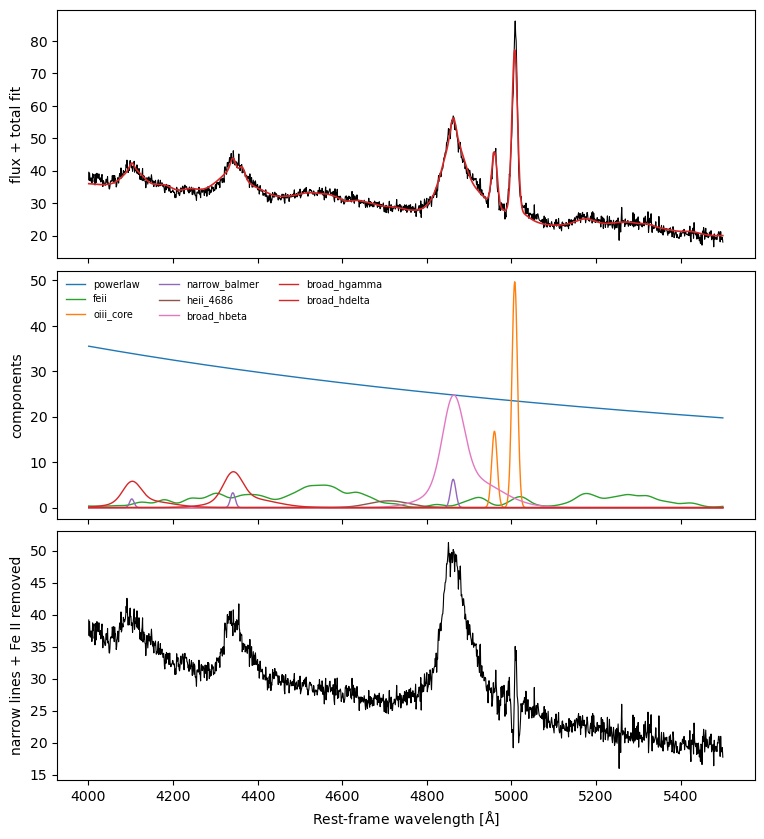

In [9]:
# load Fe II template and set up the optical region model (KPK14 Sect. 3.1)
fe_w, fe_f = load_park2022_feii()
reg = OpticalRegionModel(fe_w, fe_f, narrow_sigma_v, narrow_dv, pl_pivot=5000.0, include_wing=False)
r1 = (wave >= STAGE1_RANGE[0]) & (wave <= STAGE1_RANGE[1])
res1 = ls.fit(wave[r1], flux[r1], err[r1], reg)
print(f"stage 2 fit: chi2/dof = {res1.chi2/res1.dof:.2f}")
for k, v, e in zip(res1.param_names, res1.params, res1.param_errors):
    print(f"   {k:26s} {v:12.4g} +/- {e:.2g}")

comps1 = reg.components(wave, res1.params)
removed = reg.removable(wave, res1.params)
flux_clean = flux.copy()
in_stage1 = (wave >= STAGE1_RANGE[0]) & (wave <= STAGE1_RANGE[1])
flux_clean[in_stage1] = flux[in_stage1] - removed[in_stage1]

# diagnostic plot (analogue of KPK14 Fig. 1)
fig, axs = plt.subplots(3, 1, figsize=(9, 10), sharex=True,
gridspec_kw={"hspace": 0.05})
w1 = wave[r1]
axs[0].plot(w1, flux[r1], "k", lw=0.8)
axs[0].plot(w1, reg.model(w1, *res1.params), "C3", lw=1.2)
axs[0].set_ylabel("flux + total fit")
for k, c in zip(["powerlaw", "feii", "oiii_core", "narrow_balmer",
 "heii_4686", "broad_hbeta", "broad_hgamma", "broad_hdelta"],
["C0", "C2", "C1", "C4", "C5", "C6", "C3", "C3", "C3"]):
    axs[1].plot(w1, comps1[k][r1], lw=1.0, color=c, label=k)
axs[1].legend(fontsize=7, ncol=3, frameon=False)
axs[1].set_ylabel("components")
axs[2].plot(w1, flux_clean[r1], "k", lw=0.8)
axs[2].set_ylabel("narrow lines + Fe II removed")
axs[2].set_xlabel(r"Rest-frame wavelength [$\mathrm{\AA}$]")
fig.savefig(os.path.join(outdir, "01_stage1_cleaning.png"), dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)


## Stage 3: power law + Balmer pseudo-continuum (the KPK14 model)
### Note that we haven't fitted UV Fe II, when using this example for publications fit UV Fe II as well.

In [10]:
bal = BalmerPseudoContinuum(te=15000.0, tau_be=1.0, n_max=400, n_edge_min=6, high_n="boltzmann")
model = AGNModel(continuum_components=[PowerLaw(wave0=PL_PIVOT), bal], fitter=ls)

windows = UV_WINDOWS + [EDGE_WINDOW, RED_WINDOW]
result = model.fit_continuum(wave, flux_clean, error=err, continuum_windows=windows)
pp = result.params  # [F5100, alpha, F_Hb, sigma_v, dv]
names = ["F5100", "alpha", "F_Hbeta(series)", "sigma_v[km/s]", "dv[km/s]"]
print(f"\nstage 3 fit: chi2/dof = {result.chi2/result.dof:.2f}  (N = {result.dof + 5})")
for nm, v, e in zip(names, pp, result.param_errors):
    print(f"   {nm:16s} {v:12.5g} +/- {e:.2g}")

F5100, alpha, f_hb, sig_v, dv = pp
pl_model = PowerLaw(wave0=PL_PIVOT).model(wave, F5100, alpha)
bc_model = bal.balmer_continuum(wave, f_hb, sig_v, dv)
bl_model = bal.balmer_lines(wave, f_hb, sig_v, dv)
total_model = pl_model + bc_model + bl_model


stage 3 fit: chi2/dof = 2.13  (N = 1456)
   F5100                  22.912 +/- 0.038
   alpha                 -1.8213 +/- 0.0087
   F_Hbeta(series)        1797.8 +/- 18
   sigma_v[km/s]          2166.9 +/- 22
   dv[km/s]               312.22 +/- 21


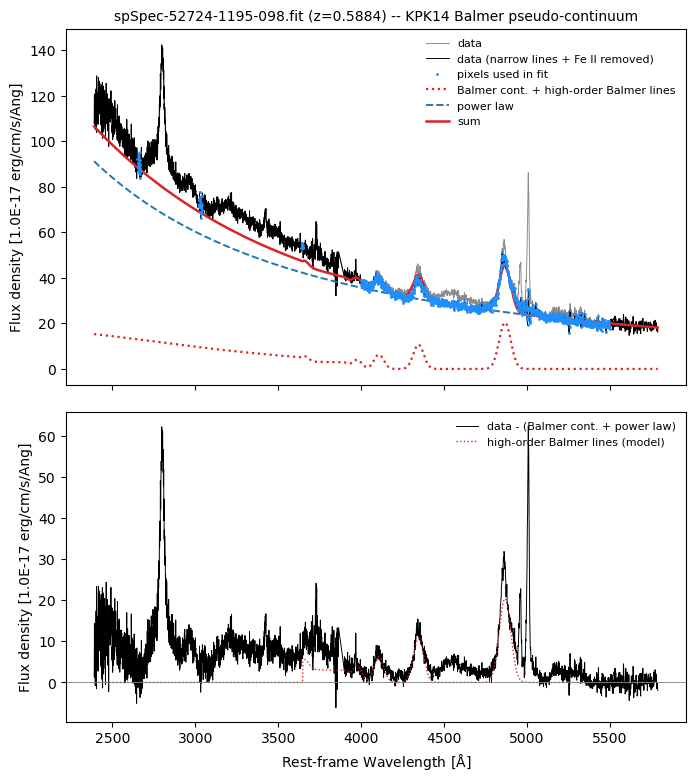

In [11]:
mask_fit = np.zeros_like(wave, bool)
for lo, hi in windows:
    mask_fit |= (wave >= lo) & (wave <= hi)

fig, axs = plot_balmer_fit(wave, flux, pl_model, bl_model, bc_model,
                           flux_clean=flux_clean, fit_mask=mask_fit, flux_unit=FLUX_UNIT,
                           title=f"{os.path.basename(input_spec)} (z={z:.4f}) -- KPK14 Balmer pseudo-continuum",
                           save=os.path.join(outdir, "02_balmer_fit_fig2_style.png"))
plt.show()

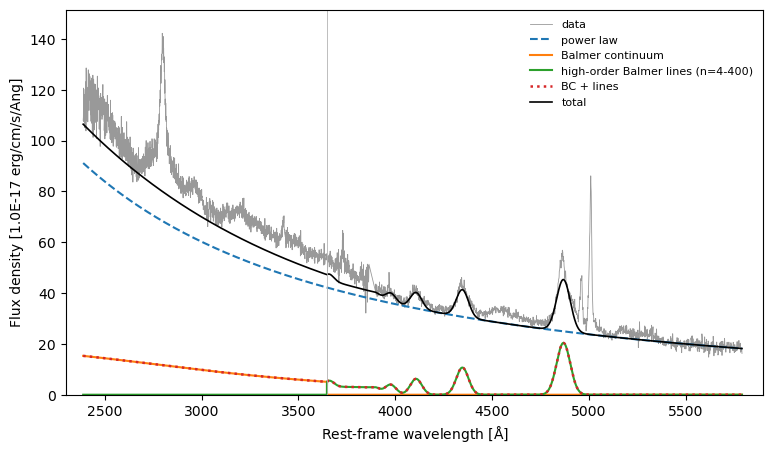

In [12]:
# the components separately
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(wave, flux, color="0.6", lw=0.6, label="data")
ax.plot(wave, pl_model, "C0--", label="power law")
ax.plot(wave, bc_model, "C1", label="Balmer continuum")
ax.plot(wave, bl_model, "C2", label="high-order Balmer lines (n=4-400)")
ax.plot(wave, bc_model + bl_model, "C3:", lw=1.8, label="BC + lines")
ax.plot(wave, total_model, "k", lw=1.2, label="total")
ax.set_xlim(2300, 5900)
ax.set_ylim(0, 1.15 * np.nanpercentile(flux, 99.5))
ax.set_xlabel(r"Rest-frame wavelength [$\mathrm{\AA}$]")
ax.set_ylabel(f"Flux density [{FLUX_UNIT}]")
ax.axvline(EDGE_VAC, color="0.7", lw=0.6)
ax.legend(frameon=False, fontsize=8)
fig.savefig(os.path.join(outdir, "03_components.png"), dpi=130, bbox_inches="tight")
plt.show()
plt.close(fig)

In [13]:
# Integrated fluxes (units: 1e-17 erg s^-1 cm^-2)
# Because only the wavelength axis was shifted, these are integrals over
# REST wavelength of the observed-frame F_lambda.  The integrated flux
# that would be measured in the observed frame is (1+z) times larger
# (dlambda_obs = (1+z) dlambda_rest).
flux_hb_series = f_hb  # single-Gaussian H-beta of the series
f1 = reg.line_fluxes(res1.params)
hb_broad_stage1 = f1["Hbeta_broad"]
# numerical integral of the Balmer-series H-beta Gaussian (sanity check)
wgrid = np.linspace(4500, 5300, 8001)
lam_hb = bal.lam_n[0] * (1 + dv / C_KMS)
s_hb = lam_hb * sig_v / C_KMS
hb_num = simpson(f_hb / (np.sqrt(2*np.pi)*s_hb) * np.exp(-0.5*((wgrid-lam_hb)/s_hb)**2), x=wgrid)

bc_cov = bal.integrated_balmer_continuum(f_hb, sig_v, dv, lam_lo=wave[0])
bc_full = bal.integrated_balmer_continuum(f_hb, sig_v, dv, lam_lo=912.0)
bc_obs_range = float(simpson(bc_model[(wave > wave[0]) & (wave <= EDGE_VAC)],
 x=wave[(wave > wave[0]) & (wave <= EDGE_VAC)]))
F_BaC = bal.f_bac(f_hb, sig_v, dv)
bc_edge = float(bal.balmer_continuum(np.array([EDGE_VAC]), f_hb, sig_v, dv)[0])

print("\n================ integrated fluxes (1e-17 erg/s/cm^2, rest-lambda integral) ==========")
print(f"  Balmer continuum, {wave[0]:.0f}-{EDGE_VAC:.0f} A (data coverage) : {bc_cov:10.1f}")
print(f"  Balmer continuum, 912-{EDGE_VAC:.0f} A (full, extrapolated)  : {bc_full:10.1f}")
print(f"  Balmer continuum flux density at the edge : {bc_edge:10.3f}  [1e-17 /A]")
print(f"  H-beta, broad, Balmer-series single Gaussian (stage 2): {flux_hb_series:10.1f}  (numeric check {hb_num:.1f})")
print(f"  H-beta, broad, 2-Gaussian profile (stage 1)   : {hb_broad_stage1:10.1f}")
print(f"  H-beta, narrow (stage 1)  : {f1['Hbeta_narrow']:10.1f}")
print(f"  BC(912-edge) / Hbeta(stage 2)  = {bc_full/flux_hb_series:6.2f};   "
  f"BC(data range) / Hbeta = {bc_cov/flux_hb_series:6.2f}")
print(f"  (multiply fluxes by (1+z) = {1+z:.4f} for the observed-frame integrated flux)")


================ integrated fluxes (1e-17 erg/s/cm^2, rest-lambda integral) ==========
  Balmer continuum, 2389-3647 A (data coverage) :    12351.2
  Balmer continuum, 912-3647 A (full, extrapolated)  :    32410.4
  Balmer continuum flux density at the edge :      5.073  [1e-17 /A]
  H-beta, broad, Balmer-series single Gaussian (stage 2):     1797.8  (numeric check 1797.8)
  H-beta, broad, 2-Gaussian profile (stage 1)   :     2364.7
  H-beta, narrow (stage 1)  :       99.1
  BC(912-edge) / Hbeta(stage 2)  =  18.03;   BC(data range) / Hbeta =   6.87
  (multiply fluxes by (1+z) = 1.5884 for the observed-frame integrated flux)


In [ ]:
# Comparison with the paper
def disc(wl, with_lines=False, half=10.0):
    m = (wave > wl - half) & (wave < wl + half)
    fobs = np.mean(flux_clean[m])
    fmod = np.mean((pl_model + bc_model + (bl_model if with_lines else 0))[m])
    return 100.0 * (fobs - fmod) / fobs

d2650 = disc(2650.0)
d4240 = disc(4240.0)
d4240_lines = disc(4240.0, with_lines=True)
print("\n================ comparison with KPK14 ===================")
print(f"  (Fobs-(Fpl+FBC))/Fobs at 2650 A : {d2650:+6.1f} %   (paper: |.|<10% for 92% of sample, Fig. 4/Table 1)")
print(f"  (Fobs-(Fpl+FBC))/Fobs at 4240 A : {d4240:+6.1f} %   (paper: |.|<10% for 91% of sample)")
print(f" same at 4240 incl. Balmer lines: {d4240_lines:+6.1f} %")
# Fig. 2 read-off (by eye from the published figure; +-10% accuracy at best)
print(f"  model BC plateau (3000-3500 A) : {np.mean(bc_model[(wave>3000)&(wave<3500)]):6.2f}   (Fig. 2: ~6-7)")
print(f"  peak of Balmer-series H-beta   : {np.max(bl_model[(wave>4700)&(wave<5050)]):6.1f}   (Fig. 2: ~23)")
print(f"  total model at 5750 A  : {total_model[np.argmin(abs(wave-5750))]:6.1f}   (Fig. 2: ~18)")
print(f"  power-law index alpha (F_lambda ~ lambda^alpha) : {alpha:6.2f}")

# ---- sensitivity: how much does the high-n (n>50) prescription matter? ----
print("\n================ sensitivity of the Balmer-edge height ====================")
sens = {}
for tag in ("boltzmann", "n3"):
    b2 = BalmerPseudoContinuum(high_n=tag)
    m2 = AGNModel(continuum_components=[PowerLaw(wave0=PL_PIVOT), b2], fitter=ls)
    r2 = m2.fit_continuum(wave, flux_clean, error=err, continuum_windows=windows)
    F5, al, fh, sv, d_v = r2.params
    bc2 = b2.balmer_continuum(wave, fh, sv, d_v)
    sens[tag] = dict(chi2_red=r2.chi2 / r2.dof, F_Hb=fh, sigma_v=sv, alpha=al,
                     BC_plateau_3000_3500=float(np.mean(bc2[(wave > 3000) & (wave < 3500)])),
    BC_912_edge=b2.integrated_balmer_continuum(fh, sv, d_v, 912.0))
    print(f"  high_n={tag:9s}: chi2r={r2.chi2/r2.dof:5.2f}  F_Hb={fh:7.1f}  sigma_v={sv:6.0f}  alpha={al:5.2f}  "
  f"BC plateau={sens[tag]['BC_plateau_3000_3500']:5.2f}  BC(912-edge)/F_Hb={sens[tag]['BC_912_edge']/fh:5.1f}")

out = dict(
file=os.path.basename(input_spec), z=z, ebv_sfd=ebv,
narrow_sigma_v=narrow_sigma_v, narrow_dv=narrow_dv,
stage1_chi2_red=res1.chi2 / res1.dof, stage2_chi2_red=result.chi2 / result.dof,
stage2_params=dict(zip(names, pp)), stage2_errors=dict(zip(names, result.param_errors)),
F_BaC=F_BaC, flux_density_BC_edge=bc_edge,
flux_BC_data_range=bc_cov, flux_BC_912_to_edge=bc_full,
flux_Hbeta_series=flux_hb_series, flux_Hbeta_broad_stage1=hb_broad_stage1,
flux_Hbeta_narrow=f1["Hbeta_narrow"],
ratio_BC_over_Hbeta=bc_full / flux_hb_series,
disc_2650_percent=d2650, disc_4240_percent=d4240,
observed_frame_factor=1 + z, sensitivity_high_n=sens, stage1_params=dict(zip(res1.param_names, res1.params)),
)

# save the summary and the arrays
io.save_results(os.path.join(outdir, "fit_summary.json"), out)
np.savetxt(os.path.join(outdir, "model_arrays.txt"),
   np.c_[wave, flux, flux_clean, err, pl_model, bc_model, bl_model, total_model],
   header="wave_rest flux_dered flux_clean err powerlaw balmer_cont balmer_lines total",
   fmt="%.6g")